## Before you start

Run `python download_data.py` once from the project folder. It downloads NASA's
FD001 files into `data/`, and the notebook only reads them — it never downloads
anything itself.

Already have a `data/` folder with `train_FD001.txt` inside? Skip this step.

## Introduction

This notebook asks one question: given an engine's sensor readings, how many cycles of life does it have left? It loads NASA's FD001 run-to-failure data, checks that the files are what they claim, labels every recorded cycle with its remaining useful life, and shows what wear looks like across 100 engines. Then it scores a deliberately simple model, plain least squares on the 14 sensors that actually move, against the dumbest possible guess.

## Imports and paths

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("data")
TRAIN = DATA / "train_FD001.txt"
TEST = DATA / "test_FD001.txt"
RUL = DATA / "RUL_FD001.txt"


In [2]:
# One role palette and one type/size scale for every figure below.
STYLE = {
    "ink": "#1A1A1A", "muted": "#595959", "faint": "#8C8C8C", "rule": "#707070",
    "grid": "#E9E9E9", "edge": "#C9C9C9", "raw": "#B0B0B0",
    "rise": "#D55E00", "fall": "#0072B2", "band": "#9E9E9E66",  # drift direction, IQR band
    "size": (11.0, 7.6), "pair": (9.9, 5.5),  # 2x2 canvas, two-panel canvas
    "title": 13, "subtitle": 9, "panel": 10.5, "label": 10, "tick": 9, "tag": 9,
}
plt.rcParams.update({
    "font.size": STYLE["label"], "axes.titlesize": STYLE["panel"], "axes.labelsize": STYLE["label"],
    "xtick.labelsize": STYLE["tick"], "ytick.labelsize": STYLE["tick"], "axes.grid": True,
    "grid.color": STYLE["grid"], "grid.linewidth": 0.8, "axes.edgecolor": STYLE["edge"],
    "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white",
})


## Load data

In [3]:
COLS = ["unit", "cycle"] + [f"setting_{i}" for i in range(1, 4)] + [f"sensor_{i}" for i in range(1, 22)]

train = pd.read_csv(TRAIN, sep=r"\s+", header=None, names=COLS)
test = pd.read_csv(TEST, sep=r"\s+", header=None, names=COLS)
rul = pd.read_csv(RUL, sep=r"\s+", header=None, names=["RUL"]).squeeze()

## Sanity check

`data/readme.txt` numbers its column list up to "sensor measurement 26", but the file has only 26 columns in total — unit + cycle + 3 operational settings + 21 sensors — so 21 sensors is the correct count and nothing was truncated.

In [4]:
for name, df in [("train", train), ("test", test)]:
    print(f"{name}: shape={df.shape} engines={df.unit.nunique()} missing={int(df.isna().sum().sum())}")
print(f"rul: shape={rul.shape} missing={int(rul.isna().sum())}")
assert len(rul) == test["unit"].nunique() == 100
print("dtypes:", train.dtypes.value_counts().to_dict())
print(train.head(5).to_string())
print(rul.head(5).to_string())

train: shape=(20631, 26) engines=100 missing=0
test: shape=(13096, 26) engines=100 missing=0
rul: shape=(100,) missing=0
dtypes: {dtype('float64'): 22, dtype('int64'): 4}
   unit  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  sensor_3  sensor_4  sensor_5  sensor_6  sensor_7  sensor_8  sensor_9  sensor_10  sensor_11  sensor_12  sensor_13  sensor_14  sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_21
0     1      1    -0.0007    -0.0004      100.0    518.67    641.82   1589.70   1400.60     14.62     21.61    554.36   2388.06   9046.19        1.3      47.47     521.66    2388.02    8138.62     8.4195       0.03        392       2388      100.0      39.06    23.4190
1     1      2     0.0019    -0.0003      100.0    518.67    642.15   1591.82   1403.14     14.62     21.61    553.75   2388.04   9044.07        1.3      47.49     522.28    2388.07    8131.49     8.4318       0.03        392       2388      100.0      39.00    23.4236
2     1      3    -

## Train RUL

In [5]:
train["RUL"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
print(train.sample(5, random_state=0).to_string())
print(train["RUL"].describe().to_string())

       unit  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  sensor_3  sensor_4  sensor_5  sensor_6  sensor_7  sensor_8  sensor_9  sensor_10  sensor_11  sensor_12  sensor_13  sensor_14  sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_21  RUL
13474    68     43     0.0003     0.0003      100.0    518.67    642.84   1585.15   1404.49     14.62     21.61    553.12   2388.10   9064.26        1.3      47.25     521.90    2388.08    8142.88     8.4486       0.03        392       2388      100.0      38.81    23.4724  156
1884      9    172     0.0041     0.0004      100.0    518.67    643.07   1593.98   1410.93     14.62     21.61    553.53   2388.01   9133.20        1.3      47.58     521.37    2388.08    8202.50     8.4565       0.03        393       2388      100.0      38.78    23.2069   29
17170    85     19    -0.0007     0.0001      100.0    518.67    642.56   1588.44   1403.63     14.62     21.61    553.79   2388.04   9043.28        1.3      47.30

## Sensor variability

In [6]:
sensors = [c for c in train.columns if c.startswith("sensor_")]
nuniq = train[sensors].nunique()
print(nuniq.to_frame("distinct").T.to_string())

dropped = [s for s in sensors if nuniq[s] <= 5]  # flat: no trend to learn
KEEP_SENSORS = [s for s in sensors if s not in dropped]
print("dropped flat sensors (<= 5 distinct values):", dropped)
print("kept sensors:", len(KEEP_SENSORS))


          sensor_1  sensor_2  sensor_3  sensor_4  sensor_5  sensor_6  sensor_7  sensor_8  sensor_9  sensor_10  sensor_11  sensor_12  sensor_13  sensor_14  sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_21
distinct         1       310      3012      4051         1         2       513        53      6403          1        159        427         56       6078       1918          1         13          1          1        120       4745
dropped flat sensors (<= 5 distinct values): ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
kept sensors: 14


## Degradation by engine

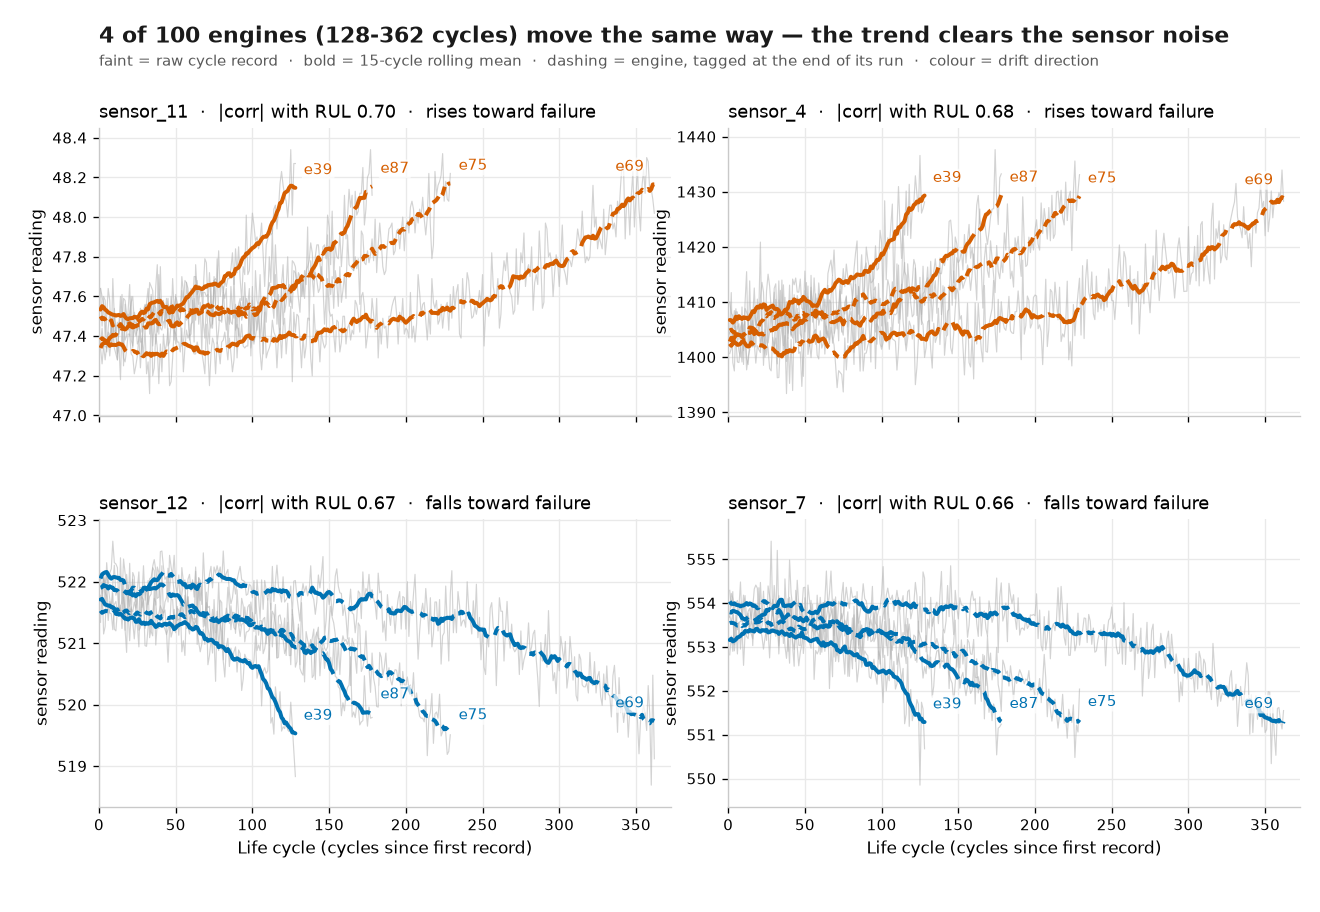

In [7]:
corr = train[KEEP_SENSORS].apply(lambda s: s.corr(train["RUL"]))
TOP = list(corr.abs().sort_values(ascending=False).head(4).index)
life = train.groupby("unit")["cycle"].max()
engines = [life.idxmin(), (life - life.quantile(0.25)).abs().idxmin(),
           (life - life.quantile(0.75)).abs().idxmin(), life.idxmax()]
ENGINE_DASH = ["-", (0, (6, 1.8)), (0, (2.2, 1.4)), (0, (9, 1.8, 2, 1.8))]
WIN = 15      # cycles in the centred rolling mean
LEFT = 0.075  # every figure starts its title and its left axis here

fig, axes = plt.subplots(2, 2, figsize=STYLE["size"], dpi=120, sharex=True)
fig.subplots_adjust(left=LEFT, right=0.985, top=0.86, bottom=0.115,
                    hspace=0.36, wspace=0.10)

for ax, s in zip(axes.ravel(), TOP):
    col = STYLE["rise"] if corr[s] < 0 else STYLE["fall"]
    for u, dash in zip(engines, ENGINE_DASH):
        d = train.loc[train["unit"] == u].sort_values("cycle")
        smooth = d[s].rolling(WIN, center=True, min_periods=3).mean()
        ax.plot(d["cycle"], d[s], color=STYLE["raw"], ls="-", lw=0.7, alpha=0.55, zorder=2)
        ax.plot(d["cycle"], smooth, color=col, ls=dash, lw=2.4, zorder=3,
                solid_capstyle="round")
        # engine tag at the end of its own trace: the longest one is placed
        # inside the axes so it cannot be clipped
        last = u == life.idxmax()
        ax.annotate(f"e{u}", (d["cycle"].iloc[-1], smooth.iloc[-1]),
                    xytext=(-6, 6) if last else (5, 6), textcoords="offset points",
                    ha="right" if last else "left", va="bottom",
                    fontsize=STYLE["tag"], color=col, zorder=4,
                    bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.72))
    ax.set_title(f"{s}  ·  |corr| with RUL {abs(corr[s]):.2f}  ·  "
                 f"{'rises' if corr[s] < 0 else 'falls'} toward failure", loc="left")
    ax.set_ylabel("sensor reading")
    ax.margins(x=0.02, y=0.09)
    ax.set_xlim(0, life.max() * 1.03)
    ax.set_axisbelow(True)

for a in axes[1, :]:
    a.set_xlabel("Life cycle (cycles since first record)")

fig.suptitle(f"{len(engines)} of {train['unit'].nunique()} engines "
             f"({int(life.min())}-{int(life.max())} cycles) move the same way — "
             f"the trend clears the sensor noise",
             x=LEFT, y=0.972, ha="left", fontsize=STYLE["title"], fontweight="bold",
             color=STYLE["ink"])
fig.text(LEFT, 0.928,
         f"faint = raw cycle record  ·  bold = {WIN}-cycle rolling mean  ·  "
         f"dashing = engine, tagged at the end of its run  ·  colour = drift direction",
         ha="left", fontsize=STYLE["subtitle"], color=STYLE["muted"])


## Fleet trend

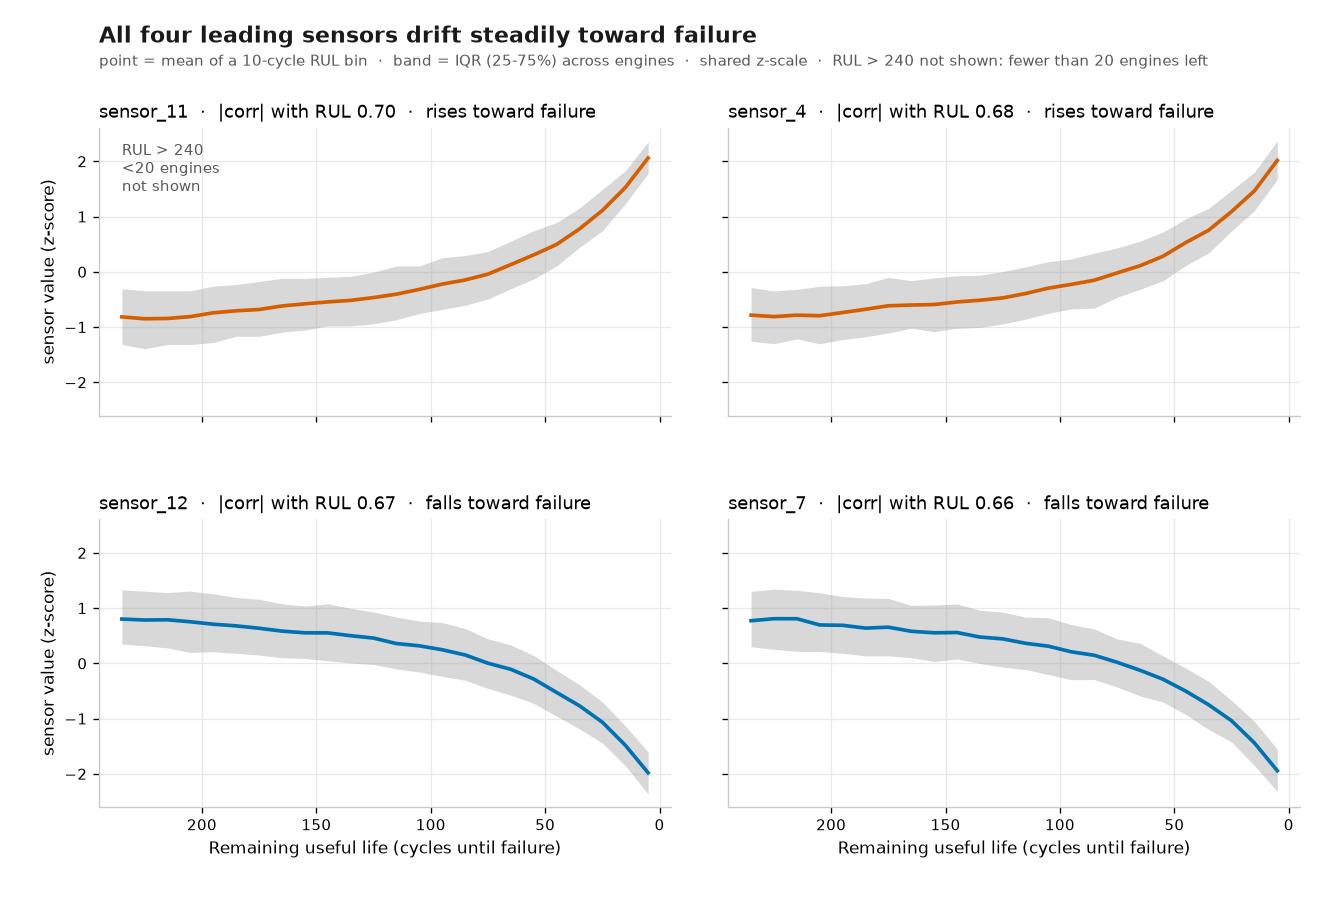

In [8]:
BIN = 10          # RUL bin width (cycles)
MIN_ENGINES = 20  # no mean is drawn where fewer engines than this remain
bins = pd.cut(train["RUL"], bins=range(0, int(train["RUL"].max()) + 20, BIN),
              include_lowest=True)
grp = train.groupby(bins, observed=True)
n_eng = grp["unit"].nunique()  # engines contributing to each RUL bin
x = np.array([b.mid for b in n_eng.index])
keep = n_eng.to_numpy() >= MIN_ENGINES
thin_from = float(n_eng.index[~keep][0].left) if (~keep).any() else float(x.max() + BIN / 2)
x_end = thin_from + BIN / 2  # padding only; the excluded tail is stated in words

fig, axes = plt.subplots(2, 2, figsize=STYLE["size"], dpi=120,
                         sharex=True, sharey=True)
fig.subplots_adjust(left=LEFT, right=0.985, top=0.86, bottom=0.115,
                    hspace=0.36, wspace=0.10)

for ax, s in zip(axes.ravel(), TOP):
    col = STYLE["rise"] if corr[s] < 0 else STYLE["fall"]
    z = (train[s] - train[s].mean()) / train[s].std()
    gz = z.groupby(bins, observed=True)
    mean = gz.mean().to_numpy()
    q1, q3 = gz.quantile(0.25).to_numpy(), gz.quantile(0.75).to_numpy()
    ax.fill_between(x[keep], q1[keep], q3[keep], color=STYLE["band"], lw=0, zorder=2)
    ax.plot(x[keep], mean[keep], color=col, lw=2.2, zorder=3)
    ax.set_title(f"{s}  ·  |corr| with RUL {abs(corr[s]):.2f}  ·  "
                 f"{'rises' if corr[s] < 0 else 'falls'} toward failure", loc="left")
    ax.set_axisbelow(True)
    ax.set_xlim(x_end, -BIN / 2)

axes[0, 0].annotate(f"RUL > {thin_from:.0f}\n<{MIN_ENGINES} engines\nnot shown",
                    xy=(0.04, 0.95), xycoords="axes fraction", fontsize=STYLE["tag"],
                    color=STYLE["muted"], ha="left", va="top")
for a in axes[:, 0]:
    a.set_ylabel("sensor value (z-score)")
for a in axes[1, :]:
    a.set_xlabel("Remaining useful life (cycles until failure)")

fig.suptitle("All four leading sensors drift steadily toward failure",
             x=LEFT, y=0.972, ha="left", fontsize=STYLE["title"], fontweight="bold",
             color=STYLE["ink"])
fig.text(LEFT, 0.928, f"point = mean of a 10-cycle RUL bin  ·  band = IQR (25-75%) "
         f"across engines  ·  shared z-scale  ·  RUL > {thin_from:.0f} not shown: "
         f"fewer than {MIN_ENGINES} engines left",
         ha="left", fontsize=STYLE["subtitle"], color=STYLE["muted"])


## Model input

The model gets one row per recorded cycle, with the 14 kept sensors as features. The target is the remaining useful life of that cycle.

In [9]:
ENGINES = np.sort(train["unit"].unique())
HOLDOUT = ENGINES[::5]  # every fifth engine: 20 units never appear in fitting

X = train[KEEP_SENSORS].to_numpy(float)
y = train["RUL"].to_numpy(float)
held = train["unit"].isin(HOLDOUT).to_numpy()

print(f"fitting rows: {int((~held).sum())}")
print(f"held-out rows: {int(held.sum())}")
print(f"held-out engines: {len(HOLDOUT)}")


fitting rows: 16262
held-out rows: 4369
held-out engines: 20


## Baseline model

Plain least squares on the 14 sensors, no tuning. Fitted only to the 80 fitting engines, scored only on the 20 held-out ones. The yardstick is `always guess the average`.

In [10]:
mean = X[~held].mean(axis=0)
std = X[~held].std(axis=0)
Z = (X - mean) / std

A = np.column_stack([np.ones(len(X)), Z])
coef = np.linalg.lstsq(A[~held], y[~held], rcond=None)[0]

pred = np.clip(A[held] @ coef, 0, None)
rmse = np.sqrt(np.mean((pred - y[held]) ** 2))

mean_y = y[~held].mean()
baseline = np.sqrt(np.mean((mean_y - y[held]) ** 2))

print(f"held-out RMSE: {rmse:.1f} cycles")
print(f"always-guess-the-average RMSE: {baseline:.1f} cycles")

held-out RMSE: 46.3 cycles
always-guess-the-average RMSE: 71.0 cycles


## Score on the real test set

The test engines stop part-way through life, so we predict once from each engine's last recorded cycle and compare with the 100 true values in `RUL_FD001.txt`; this is the number the README quotes. Predictions below zero are raised to zero because negative remaining life is impossible.

The 46.3 above and this 30.2 are different populations, so they are not comparable: 46.3 averages every cycle of every held-out engine (mean RUL 113), while 30.2 is one row per engine at its last recorded cycle (mean RUL 75.5). The like-for-like number is the `RUL<=145` print below, 27.9 against 54.1.

In [11]:
last = test.sort_values(["unit", "cycle"]).groupby("unit").tail(1)
Zt = (last[KEEP_SENSORS].to_numpy(float) - mean) / std
pred_test = np.clip(np.column_stack([np.ones(len(last)), Zt]) @ coef, 0, None)
RUL_BY_UNIT = pd.Series(rul.to_numpy(float), index=np.arange(1, 101))
truth = RUL_BY_UNIT.loc[last["unit"]].to_numpy(float)
assert len(truth) == len(last)

rmse_test = np.sqrt(np.mean((pred_test - truth) ** 2))
baseline_test = np.sqrt(np.mean((mean_y - truth) ** 2))

print(f"test RMSE: {rmse_test:.1f} cycles")
print(f"always-guess-the-average RMSE on test: {baseline_test:.1f} cycles")
print(f"mean prediction {pred_test.mean():.1f} vs mean truth {truth.mean():.1f} cycles")

matched = held & (y <= 145)  # held-out cycles in the test set's own life range
pred_matched = np.clip(A[matched] @ coef, 0, None)
rmse_matched = np.sqrt(np.mean((pred_matched - y[matched]) ** 2))
baseline_matched = np.sqrt(np.mean((mean_y - y[matched]) ** 2))

print(f"held-out RMSE, RUL<=145 only: {rmse_matched:.1f} cycles")
print(f"always-guess-the-average on the same rows: {baseline_matched:.1f} cycles")

test RMSE: 30.2 cycles
always-guess-the-average RMSE on test: 51.8 cycles
mean prediction 94.3 vs mean truth 75.5 cycles
held-out RMSE, RUL<=145 only: 27.9 cycles
always-guess-the-average on the same rows: 54.1 cycles


## Where the model fails

The model leans high: on average it over-predicts by 18.8 cycles, and the lean is positive at every age, but it peaks in mid-life — about +40 cycles with roughly 70 left — and shrinks to about +8 close to failure and +3 early in life. That bias accounts for 39% of the squared error; the other 61% is scatter, which is what the second panel shows. Both panels show the same 100 test engines as points, not lines.

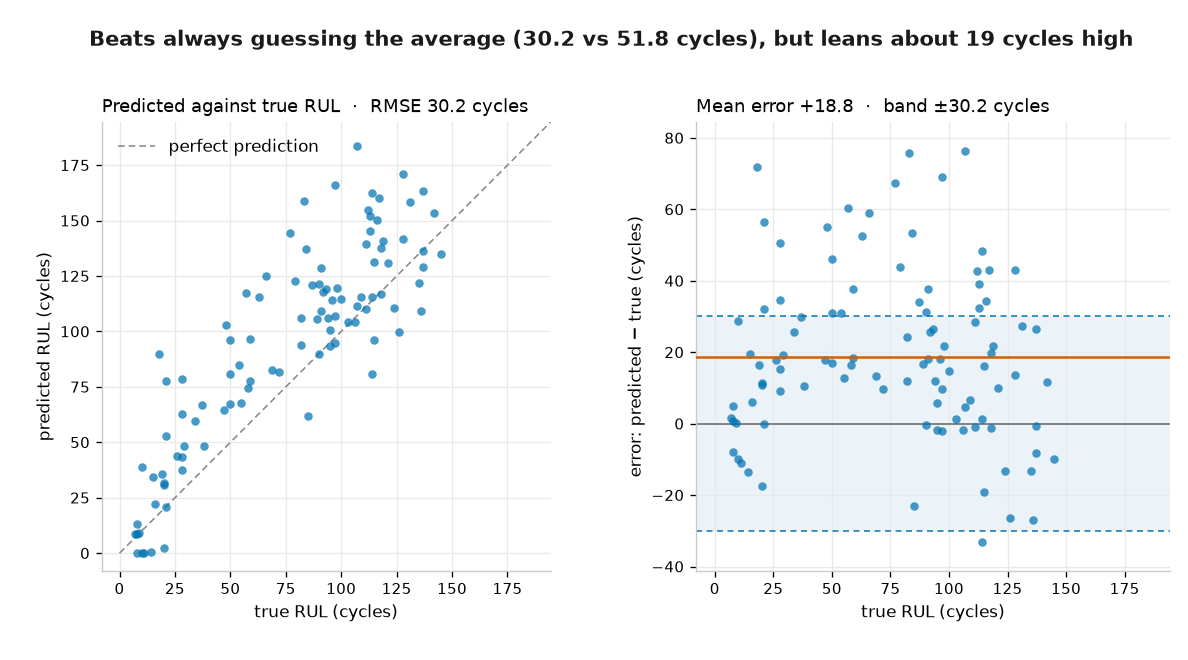

In [12]:
err = pred_test - truth
bias = float(err.mean())
EDGE_PAD = 8.0  # small margin so the clipped-at-zero predictions stay whole
SPAN_PAD = 1.06  # room for the point at the top-right of the diagonal
lo = -EDGE_PAD
span = float(max(truth.max(), pred_test.max())) * SPAN_PAD
y_lo, y_hi = float(err.min()) - EDGE_PAD, float(err.max()) + EDGE_PAD

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=STYLE["pair"], dpi=120)
fig.subplots_adjust(left=LEFT, right=0.985, top=0.815, bottom=0.135, wspace=0.28)

# Panel 1: the same point cloud the RMSE is computed on, against the perfect diagonal.
ax1.plot([0, span], [0, span], color=STYLE["faint"], lw=1.0, ls=(0, (4, 2.4)),
         label="perfect prediction", zorder=1)
ax1.scatter(truth, pred_test, s=26, color=STYLE["fall"], alpha=0.72, linewidths=0, zorder=2)
ax1.set_xlim(lo, span)
ax1.set_ylim(lo, span)
ax1.set_aspect("equal", adjustable="box")
ax1.set_xlabel("true RUL (cycles)")
ax1.set_ylabel("predicted RUL (cycles)")
ax1.set_title(f"Predicted against true RUL  ·  RMSE {rmse_test:.1f} cycles", loc="left")
ax1.legend(loc="upper left", frameon=False, handlelength=2.2, borderaxespad=0.6)
ax1.set_axisbelow(True)

# Panel 2: error only. Dashed band = the scored RMSE, orange line = the lean.
ax2.axhspan(-rmse_test, rmse_test, color=STYLE["fall"], alpha=0.08, lw=0, zorder=0)
for edge in (-rmse_test, rmse_test):
    ax2.axhline(edge, color=STYLE["fall"], lw=0.9, ls=(0, (4, 3)), zorder=1)
ax2.axhline(0, color=STYLE["rule"], lw=1.0, zorder=1)
ax2.axhline(bias, color=STYLE["rise"], lw=1.5, zorder=3)
ax2.scatter(truth, err, s=26, color=STYLE["fall"], alpha=0.72, linewidths=0, zorder=2)
ax2.set_xlim(lo, span)
ax2.set_ylim(y_lo, y_hi)
ax2.set_xlabel("true RUL (cycles)")
ax2.set_ylabel("error: predicted − true (cycles)")
ax2.set_title(f"Mean error {bias:+.1f}  ·  band ±{rmse_test:.1f} cycles", loc="left")
ax2.set_axisbelow(True)

fig.suptitle(f"Beats always guessing the average ({rmse_test:.1f} vs {baseline_test:.1f} cycles), "
             f"but leans about {bias:.0f} cycles high",
             x=LEFT, y=0.955, ha="left", fontsize=12.5, fontweight="bold", color=STYLE["ink"])


## Operating conditions in FD002

In [13]:
from sklearn.cluster import KMeans

SETTINGS = ["setting_1", "setting_2", "setting_3"]
SENSORS = [c for c in COLS if c.startswith("sensor_")]

probe = pd.read_csv(DATA / "train_FD002.txt", sep=r"\s+", header=None, names=COLS)
grid = probe[SETTINGS].to_numpy(float)
combos = probe[SETTINGS].round(1).drop_duplicates().shape[0]
inertia = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(grid).inertia_ for k in range(1, 9)]
print(f"FD002 rows {len(probe):,}, distinct settings at 1 dp: {combos}")
print("k       " + "".join(f"{k:>10}" for k in range(1, 9)))
print("inertia " + "".join(f"{v:>10.4g}" for v in inertia))
print("ratio   " + "".join(f"{p:>10.3g}" for p in np.array(inertia[1:]) / np.array(inertia[:-1])))

FD002 rows 53,759, distinct settings at 1 dp: 7
k                1         2         3         4         5         6         7         8
inertia  2.259e+07 1.169e+07 1.865e+06 6.504e+05 2.466e+05    0.4107    0.3255    0.2743
ratio        0.517      0.16     0.349     0.379  1.67e-06     0.793     0.843


## Data layer: condition labels, per-condition z-score, loader

In [14]:
CONDITIONS = {"FD001": 1, "FD002": 6, "FD003": 1, "FD004": 6}   # FD002 inertia falls 2.5e5 -> 0.4 from k=5 to k=6
FLAT = 1e-9   # a sensor that does not move inside a condition stays at 0 instead of exploding


def load_subset(name):
    """train, test, last-cycle test rows, RUL. Sensors are z-scored inside each operating condition."""
    def read(kind):
        return pd.read_csv(DATA / f"{kind}_{name}.txt", sep=r"\s+", header=None, names=COLS)

    train_sub, test_sub = read("train"), read("test")
    rul = pd.read_csv(DATA / f"RUL_{name}.txt", header=None, names=["RUL"]).squeeze()

    km = KMeans(n_clusters=CONDITIONS[name], n_init=10, random_state=0).fit(train_sub[SETTINGS].to_numpy(float))
    train_sub["condition"] = km.labels_
    test_sub["condition"] = km.predict(test_sub[SETTINGS].to_numpy(float))

    # train statistics only; labels are 0..k-1 so [labels] broadcasts the right row onto every reading
    mean = train_sub.groupby("condition")[SENSORS].mean()
    std = train_sub.groupby("condition")[SENSORS].std().mask(lambda s: s <= FLAT, 1.0)
    for frame in (train_sub, test_sub):
        labels = frame["condition"].to_numpy()
        frame[SENSORS] = (frame[SENSORS].to_numpy(float) - mean.to_numpy()[labels]) / std.to_numpy()[labels]

    train_sub["RUL"] = train_sub.groupby("unit")["cycle"].transform("max") - train_sub["cycle"]
    last = test_sub.sort_values(["unit", "cycle"]).groupby("unit").tail(1).reset_index(drop=True)
    return train_sub, test_sub, last, rul

## One condition must be a no-op

In [15]:
fd001 = load_subset("FD001")[0]
moving = [s for s in SENSORS if train[s].std() > FLAT]
before = (train[moving] - train[moving].mean()) / train[moving].std()
print(f"FD001: {len(moving)} moving sensors, max |within-condition - global| = "
      f"{np.abs(fd001[moving].to_numpy() - before.to_numpy()).max():.1e}")

fd002, test002, last002, rul002 = load_subset("FD002")
print(f"FD002: train {fd002.shape}, test {test002.shape}, last {last002.shape}, "
      f"RUL {len(rul002)}, conditions {fd002['condition'].nunique()}")

FD001: 15 moving sensors, max |within-condition - global| = 9.0e-11
FD002: train (53759, 28), test (33991, 27), last (259, 27), RUL 259, conditions 6


## Conclusions

Fourteen of the 21 sensors carry the story: some climb steadily as an engine wears, others fall. A straight line through them already reaches an RMSE of 30.2 cycles on the 100 official test engines, against 51.8 for always guessing the fleet average, so the signal is real and a baseline is enough to prove it. The model is also systematically optimistic, about 19 cycles high, worst with 40-80 cycles of life left. That bias, more than the scatter, is what a better model should attack first.